# Exploratory data analysis: Arctic sea ice, temperature and CO2

This notebook looks at the data before we answer the three research questions.
Run `python scripts/download_data.py` and `python scripts/preprocess.py` first; the
notebook reads `data/raw/` (first contact) and `data/processed/` (everything else).

1. **First contact** - types, a sample, identifiers, duplicates, missing values, date ranges
2. **One variable at a time** - summary statistics, distributions, values over time
3. **Relationships** - correlations and scatter plots between ice, temperature and CO2
4. **Findings**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from preprocess import load_ice_daily, load_gistemp  # same loading code as the pipeline

# The notebook lives in scripts/; the data folder is one level up.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"

sns.set_theme(style="whitegrid", palette="colorblind")  # colour-blind-safe palette
pd.set_option("display.width", 120)
SOURCE_NOTE = "Sources: NSIDC Sea Ice Index G02135 v4, NASA GISTEMP v4, NOAA GML Mauna Loa CO2"

## 1. First contact

### 1.1 Types and a random sample of each dataset

In [2]:
ice = load_ice_daily()
nh = load_gistemp("gistemp_nh_monthly.csv", "nh_anomaly")
glob = load_gistemp("gistemp_global_monthly.csv", "global_anomaly")
co2_raw = pd.read_csv(ROOT / "data" / "raw" / "noaa_co2_monthly.csv", comment="#")

for name, table in [("Sea ice (daily)", ice), ("GISTEMP NH (monthly)", nh),
                    ("GISTEMP global (monthly)", glob), ("NOAA CO2 (monthly)", co2_raw)]:
    print(f"=== {name}: {table.shape[0]} rows x {table.shape[1]} columns")
    print(table.dtypes.to_string())
    print()

=== Sea ice (daily): 15903 rows x 5 columns
date      datetime64[us]
year               int64
month              int64
day                int64
extent           float64

=== GISTEMP NH (monthly): 1762 rows x 3 columns
year            int64
month           int64
nh_anomaly    float64

=== GISTEMP global (monthly): 1762 rows x 3 columns
year                int64
month               int64
global_anomaly    float64

=== NOAA CO2 (monthly): 823 rows x 8 columns
year                int64
month               int64
decimal date      float64
average           float64
deseasonalized    float64
ndays               int64
sdev              float64
unc               float64



In [3]:
ice.sample(5, random_state=421)

,date,year,month,day,extent
15893,2026-11-07,2026,11,7,8.547
2343,1989-10-02,1989,10,2,7.493
4952,1996-11-23,1996,11,23,10.827
8847,2007-07-24,2007,7,24,7.126
4034,1994-05-20,1994,5,20,13.502


In [4]:
co2_raw.sample(5, random_state=421)

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
368,1988,11,1988.8750,350.42,352.53,25,0.20,0.08
278,1981,5,1981.3750,343.04,339.97,30,0.19,0.07
298,1983,1,1983.0417,341.57,341.75,28,0.47,0.17
202,1975,1,1975.0417,330.73,330.84,29,0.43,0.15
732,2019,3,2019.2083,412.18,410.71,28,1.12,0.40


### 1.2 Identifiers and duplicates
A row is identified by its **date** (sea ice) or by **year + month** (temperature, CO2).
We check that no identifier appears twice.

In [5]:
print("Sea ice: duplicated dates            ", ice["date"].duplicated().sum())
print("GISTEMP NH: duplicated year-months    ", nh.duplicated(["year", "month"]).sum())
print("GISTEMP global: duplicated year-months", glob.duplicated(["year", "month"]).sum())
print("CO2: duplicated year-months           ", co2_raw.duplicated(["year", "month"]).sum())

Sea ice: duplicated dates             0
GISTEMP NH: duplicated year-months     0
GISTEMP global: duplicated year-months 0
CO2: duplicated year-months            0


### 1.3 Missing values
Missing values here are mostly **missing rows** (days or months that were never measured),
not empty cells, so we count rows per year as well as empty cells.

In [6]:
print("Empty cells per column")
print("  sea ice:", ice.isna().sum().to_dict())
print("  CO2:    ", co2_raw.isna().sum().to_dict())

days_per_year = ice.groupby("year").size()
print()
print("Sea ice: measured days per year, 1978-1990")
print(days_per_year.loc[1978:1990].to_string())

Empty cells per column
  sea ice: {'date': 0, 'year': 0, 'month': 0, 'day': 0, 'extent': 0}
  CO2:     {'year': 0, 'month': 0, 'decimal date': 0, 'average': 0, 'deseasonalized': 0, 'ndays': 0, 'sdev': 0, 'unc': 0}

Sea ice: measured days per year, 1978-1990
year
1978     34
1979    182
1980    183
1981    183
1982    182
1983    183
1984    183
1985    182
1986    183
1987    220
1988    354
1989    365
1990    365


In [7]:
# Longest gaps between two measured days
gap_days = ice["date"].diff().dt.days
longest = ice.assign(gap_days=gap_days).nlargest(4, "gap_days")
longest["last_day_before_gap"] = longest["date"] - pd.to_timedelta(longest["gap_days"], unit="D")
longest[["last_day_before_gap", "date", "gap_days"]]

,last_day_before_gap,date,gap_days
1715,1987-12-02,1988-01-13,42.0
1,1978-10-26,1978-10-28,2.0
2,1978-10-28,1978-10-30,2.0
3,1978-10-30,1978-11-01,2.0


In [8]:
# GISTEMP: months without a value yet (marked *** in the raw file, dropped when loading)
raw_nh = pd.read_csv(ROOT / "data" / "raw" / "gistemp_nh_monthly.csv", skiprows=1, na_values="***")
print("GISTEMP NH: the last year in the file has", raw_nh.iloc[-1, 1:13].isna().sum(), "empty months")

# CO2: ndays = -1 means NOAA had no daily data that month and filled the value in
no_daily = co2_raw[co2_raw["ndays"] < 0]
print("CO2: months with ndays = -1:", len(no_daily), "| years:", sorted(no_daily["year"].unique()))

GISTEMP NH: the last year in the file has 2 empty months
CO2: months with ndays = -1: 195 | years: [np.int64(1958), np.int64(1959), np.int64(1960), np.int64(1961), np.int64(1962), np.int64(1963), np.int64(1964), np.int64(1965), np.int64(1966), np.int64(1967), np.int64(1968), np.int64(1969), np.int64(1970), np.int64(1971), np.int64(1972), np.int64(1973), np.int64(1974), np.int64(1975)]


### 1.4 Date ranges and overlap

In [9]:
print("Sea ice:", ice["date"].min().date(), "to", ice["date"].max().date())
print("GISTEMP:", nh["year"].min(), "to", nh["year"].max(), "(monthly)")
print("CO2:    ", co2_raw["year"].min(), "to", co2_raw["year"].max(), "(monthly)")
print("All three overlap from 1979; joined table:")
monthly = pd.read_csv(PROCESSED / "monthly_joined.csv")
print("  ", monthly["year"].min(), "-", monthly["year"].max(), "|", len(monthly), "months")

Sea ice: 1978-10-26 to 2026-11-16
GISTEMP: 1880 to 2026 (monthly)
CO2:     1958 to 2026 (monthly)
All three overlap from 1979; joined table:
   1979 - 2026 | 573 months


## 2. One variable at a time

In [10]:
yearly = pd.read_csv(PROCESSED / "yearly.csv")
monthly[["ice_extent", "nh_anomaly", "global_anomaly", "co2_ppm"]].describe().round(2)

,ice_extent,nh_anomaly,global_anomaly,co2_ppm
count,573.00,573.00,573.00,573.00
mean,11.29,0.68,0.58,377.70
std,3.29,0.47,0.33,26.91
min,3.57,-0.42,-0.10,333.97
25%,8.46,0.33,0.33,354.42
50%,12.02,0.65,0.55,374.30
75%,14.19,1.01,0.80,399.27
max,16.34,1.96,1.48,432.34


### 2.1 Distribution of daily sea-ice extent

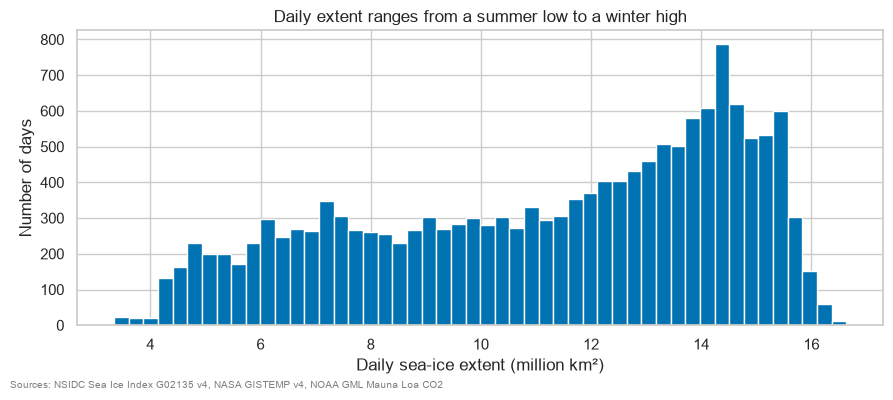

In [11]:
recent = ice[(ice["year"] >= 1979) & (ice["year"] <= 2025)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(recent["extent"], bins=50)
ax.set_xlabel("Daily sea-ice extent (million km²)")
ax.set_ylabel("Number of days")
ax.set_title("Daily extent ranges from a summer low to a winter high")
fig.text(0.01, 0.01, SOURCE_NOTE, fontsize=7, color="gray")
plt.tight_layout()
plt.show()

### 2.2 The yearly cycle: 1980s compared with the 2010s

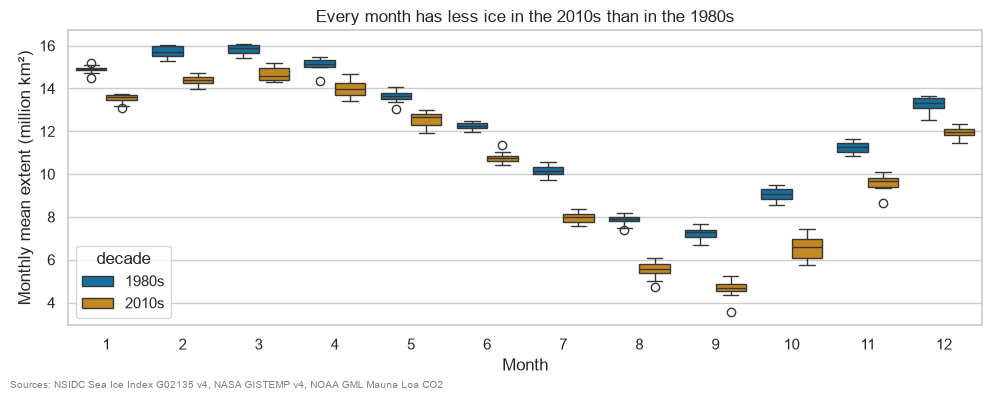

decade,1980s,2010s,loss_million_km2,loss_percent
month,,,,
1,14.90,13.52,1.38,9.27
2,15.72,14.37,1.35,8.58
3,15.84,14.66,1.18,7.43
4,15.12,14.02,1.09,7.23
5,13.64,12.57,1.07,7.87
6,12.24,10.78,1.46,11.93
7,10.14,7.98,2.16,21.32
8,7.86,5.53,2.33,29.65
9,7.21,4.65,2.55,35.43


In [12]:
by_month = monthly.copy()
by_month["decade"] = (by_month["year"] // 10 * 10).astype(str) + "s"
two_decades = by_month[by_month["decade"].isin(["1980s", "2010s"])]
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=two_decades, x="month", y="ice_extent", hue="decade", ax=ax)
ax.set_xlabel("Month")
ax.set_ylabel("Monthly mean extent (million km²)")
ax.set_title("Every month has less ice in the 2010s than in the 1980s")
fig.text(0.01, 0.01, SOURCE_NOTE, fontsize=7, color="gray")
plt.tight_layout()
plt.show()

loss = two_decades.groupby(["month", "decade"])["ice_extent"].mean().unstack()
loss["loss_million_km2"] = loss["1980s"] - loss["2010s"]
loss["loss_percent"] = 100 * loss["loss_million_km2"] / loss["1980s"]
loss.round(2)

### 2.3 Values over time

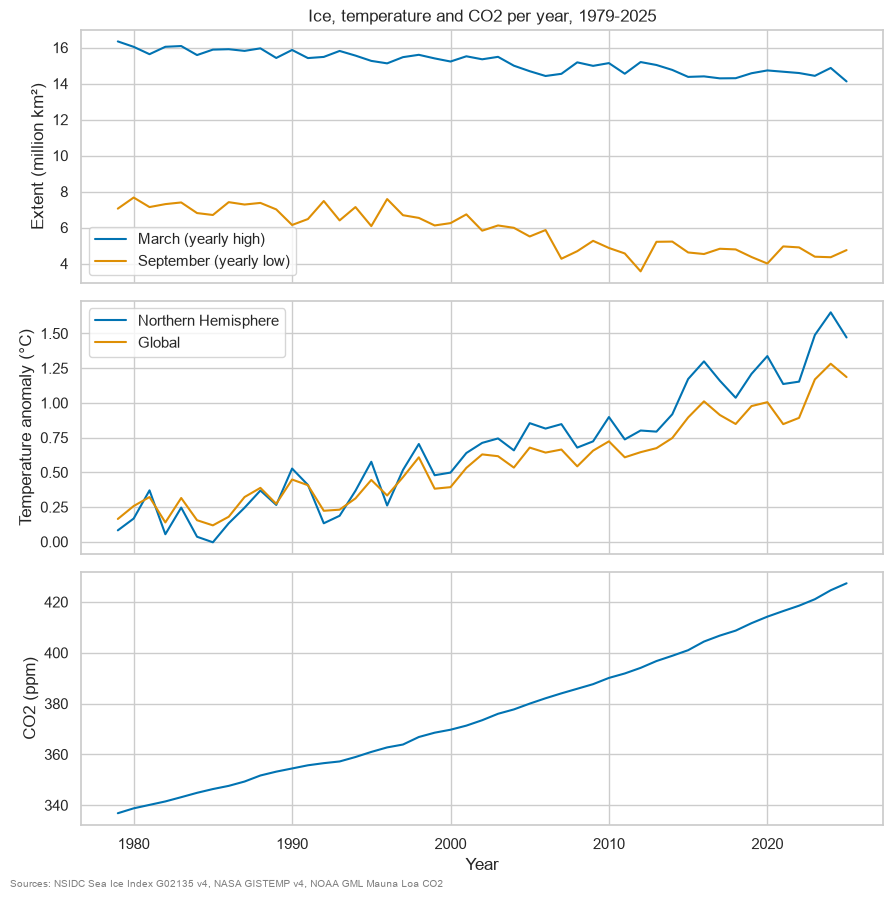

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
axes[0].plot(yearly["year"], yearly["march_ice_extent"], label="March (yearly high)")
axes[0].plot(yearly["year"], yearly["september_ice_extent"], label="September (yearly low)")
axes[0].set_ylabel("Extent (million km²)")
axes[0].legend()
axes[0].set_title("Ice, temperature and CO2 per year, 1979-2025")
axes[1].plot(yearly["year"], yearly["nh_annual_anomaly"], label="Northern Hemisphere")
axes[1].plot(yearly["year"], yearly["global_annual_anomaly"], label="Global")
axes[1].set_ylabel("Temperature anomaly (°C)")
axes[1].legend()
axes[2].plot(yearly["year"], yearly["co2_annual_mean"])
axes[2].set_ylabel("CO2 (ppm)")
axes[2].set_xlabel("Year")
fig.text(0.01, 0.005, SOURCE_NOTE, fontsize=7, color="gray")
plt.tight_layout()
plt.show()

In [14]:
# Change per decade from a straight-line fit, so the series can be compared in numbers
first_decade = yearly[yearly["year"] <= 1988]
for column, unit in [("september_ice_extent", "million km²"), ("march_ice_extent", "million km²"),
                     ("nh_annual_anomaly", "°C"), ("global_annual_anomaly", "°C"),
                     ("co2_annual_mean", "ppm")]:
    per_decade = 10 * np.polyfit(yearly["year"], yearly[column], 1)[0]
    line = f"{column:24s} {per_decade:+8.3f} {unit} per decade"
    if "extent" in column:
        line += f"  ({100 * per_decade / first_decade[column].mean():+.1f}% of the 1979-1988 mean)"
    print(line)

september_ice_extent       -0.761 million km² per decade  (-10.5% of the 1979-1988 mean)
march_ice_extent           -0.380 million km² per decade  (-2.4% of the 1979-1988 mean)
nh_annual_anomaly          +0.296 °C per decade
global_annual_anomaly      +0.206 °C per decade
co2_annual_mean           +19.221 ppm per decade


### 2.4 Unusual values

In [15]:
# Lowest September extents on record
yearly.nsmallest(5, "september_ice_extent")[["year", "september_ice_extent"]]

,year,september_ice_extent
33,2012,3.566
41,2020,4.001
28,2007,4.267
45,2024,4.351
40,2019,4.364


In [16]:
# Years far from the trend: September extent minus the straight-line fit
trend = np.polyval(np.polyfit(yearly["year"], yearly["september_ice_extent"], 1), yearly["year"])
yearly["september_residual"] = yearly["september_ice_extent"] - trend
sd = yearly["september_residual"].std()
print(f"Residual SD: {sd:.2f} million km². Years more than 2 SD away from the trend:")
yearly.loc[yearly["september_residual"].abs() > 2 * sd,
           ["year", "september_ice_extent", "september_residual"]].round(2)

Residual SD: 0.52 million km². Years more than 2 SD away from the trend:


,year,september_ice_extent,september_residual
17,1996,7.58,1.25
28,2007,4.27,-1.23
33,2012,3.57,-1.55


## 3. Relationships

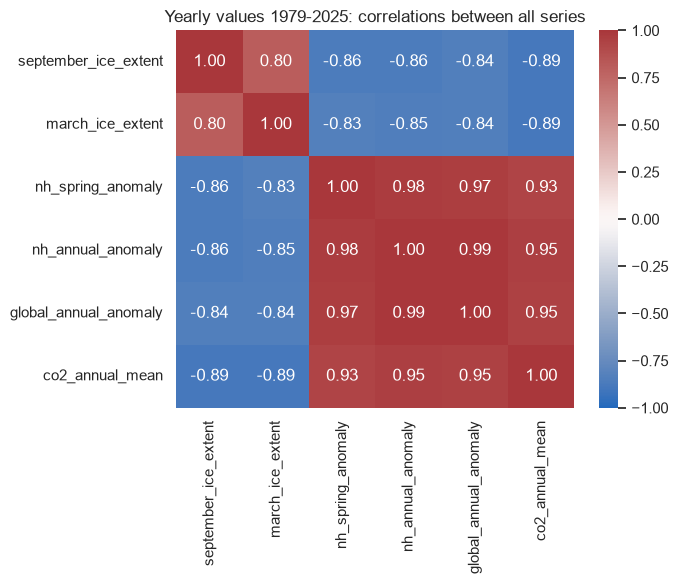

In [17]:
columns = ["september_ice_extent", "march_ice_extent", "nh_spring_anomaly",
           "nh_annual_anomaly", "global_annual_anomaly", "co2_annual_mean"]
corr = yearly[columns].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Yearly values 1979-2025: correlations between all series")
plt.tight_layout()
plt.show()

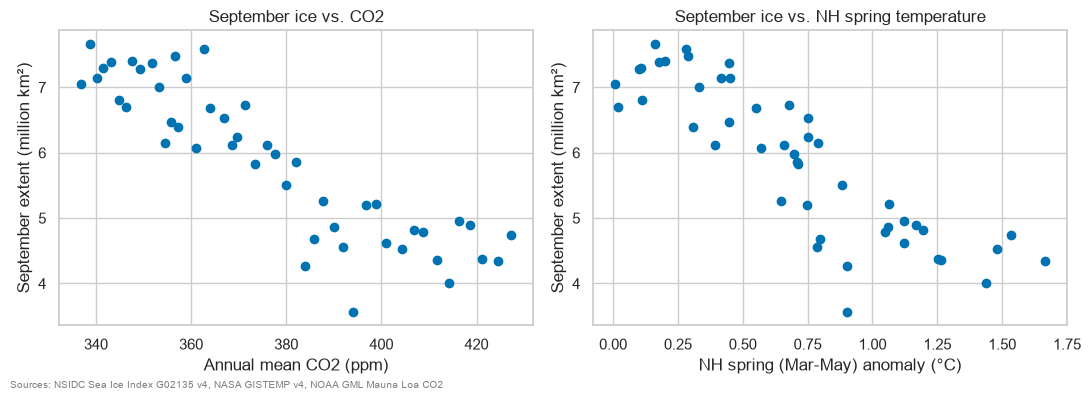

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(yearly["co2_annual_mean"], yearly["september_ice_extent"])
axes[0].set_xlabel("Annual mean CO2 (ppm)")
axes[0].set_ylabel("September extent (million km²)")
axes[0].set_title("September ice vs. CO2")
axes[1].scatter(yearly["nh_spring_anomaly"], yearly["september_ice_extent"])
axes[1].set_xlabel("NH spring (Mar-May) anomaly (°C)")
axes[1].set_ylabel("September extent (million km²)")
axes[1].set_title("September ice vs. NH spring temperature")
fig.text(0.01, 0.01, SOURCE_NOTE, fontsize=7, color="gray")
plt.tight_layout()
plt.show()

### 3.1 A warning for question 2: shared trends
Ice, temperature and CO2 all change steadily with time, so any two of them look strongly
related even if one does not affect the other. A first check: remove the straight-line
trend from each series and correlate what is left (the year-to-year ups and downs).

In [19]:
def detrend(values):
    fitted = np.polyval(np.polyfit(yearly["year"], values, 1), yearly["year"])
    return values - fitted


rows = []
for x in ["nh_spring_anomaly", "nh_annual_anomaly", "co2_annual_mean"]:
    rows.append({
        "compared with september_ice_extent": x,
        "raw_correlation": yearly[x].corr(yearly["september_ice_extent"]),
        "detrended_correlation": np.corrcoef(detrend(yearly[x]),
                                             detrend(yearly["september_ice_extent"]))[0, 1],
    })
pd.DataFrame(rows).round(2)

,compared with september_ice_extent,raw_correlation,detrended_correlation
0,nh_spring_anomaly,-0.86,-0.19
1,nh_annual_anomaly,-0.86,-0.11
2,co2_annual_mean,-0.89,0.01


## 4. Findings

**Data quality**
- No duplicated dates or year-months and no empty cells in any dataset. Missing data appears as **missing rows**: sea ice was measured only every other day until August 1987 (about 183 days per year), and there is one 42-day gap from 2 December 1987 to 13 January 1988. Question 1 fills the single missing days; `scripts/q1_method_check.py` tests that choice.
- GISTEMP has no values yet for the last two months of 2026. CO2 months filled in by NOAA (`ndays = -1`) are all before 1976, so they are outside our 1979-2025 period.

**One variable at a time**
- Ice is lost in **every month**, but not equally: from the 1980s to the 2010s September lost 2.55 million km² (35%), while April lost 1.09 million km² (7%). The summer low is falling much faster than the winter high, so the yearly cycle is getting deeper.
- Straight-line trends 1979-2025: September extent -0.76 million km² per decade (-10.5% of its 1979-1988 mean per decade), March extent -0.38 million km² per decade (-2.4%). The Northern Hemisphere warms by +0.30 °C per decade, faster than the globe (+0.21 °C). CO2 rises by about 19 ppm per decade.
- Unusual years: 2012 is the record September low (3.57 million km²). 2012 and 2007 are more than 2 standard deviations below the trend line; 1996 is more than 2 standard deviations above it.

**Relationships**
- September ice is strongly correlated with NH spring temperature (r = -0.86), NH annual temperature (r = -0.86) and CO2 (r = -0.89).
- Most of this comes from the shared trend over time: after removing the straight-line trend from each series the correlations fall to -0.19, -0.11 and 0.01. With 47 years, a correlation needs to be larger than about 0.29 in size to be significant at the 5% level, so none of the year-to-year links is clear yet. Question 2 must therefore be answered on year-to-year changes, not on the raw values.